# Practical No. 8
## Classification using Decision Tree and Naïve Bayes

**CO2, CO3**

### Aim
To implement Decision Tree and Naïve Bayes classifiers using the provided Kaggle Iris CSV dataset, compare their performance using standard evaluation metrics, and identify the most suitable model.

## Dataset
The practical uses the uploaded **Kaggle Iris.csv** file.

The dataset contains measurements of iris flowers and a categorical target variable representing the species.

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Import Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB

## Import Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Load Kaggle CSV Dataset

In [4]:
# Read the Kaggle Iris CSV file
df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# Display Dataset Shape
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 150
Columns: 6


In [6]:
# Display Column Names
print(df.columns.tolist())

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [7]:
# Display Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [8]:
# Check Missing Values
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [9]:
# Display Class Distribution
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

## Data Preprocessing

In [10]:
# Remove the Id Column
df = df.drop("Id", axis=1)

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [11]:
# Separate Features and Target
X = df.drop("Species", axis=1)
y = df["Species"]

In [12]:
# Encode Target Classes
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Encoded Classes:", label_encoder.classes_)

Encoded Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [13]:
# Display Feature and Target Shapes
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (150, 4)
Target Shape: (150,)


## Split Dataset

In [14]:
# Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [15]:
# Display Training and Testing Samples
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 120
Testing Samples: 30


# Decision Tree Classifier

In [16]:
# Create Decision Tree Model
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

In [17]:
# Train Decision Tree
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [18]:
# Predict Test Data
dt_pred = dt.predict(X_test)

In [19]:
# Calculate Decision Tree Metrics
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, average="weighted")
dt_recall = recall_score(y_test, dt_pred, average="weighted")
dt_f1 = f1_score(y_test, dt_pred, average="weighted")

print("Decision Tree")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1-Score :", dt_f1)

Decision Tree
Accuracy : 0.9333333333333333
Precision: 0.9333333333333333
Recall   : 0.9333333333333333
F1-Score : 0.9333333333333333


In [20]:
# Decision Tree Classification Report
print(
    classification_report(
        y_test,
        dt_pred,
        target_names=label_encoder.classes_
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



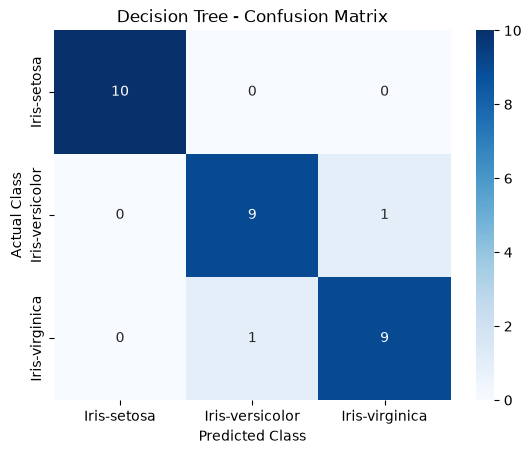

In [21]:
# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(y_test, dt_pred)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

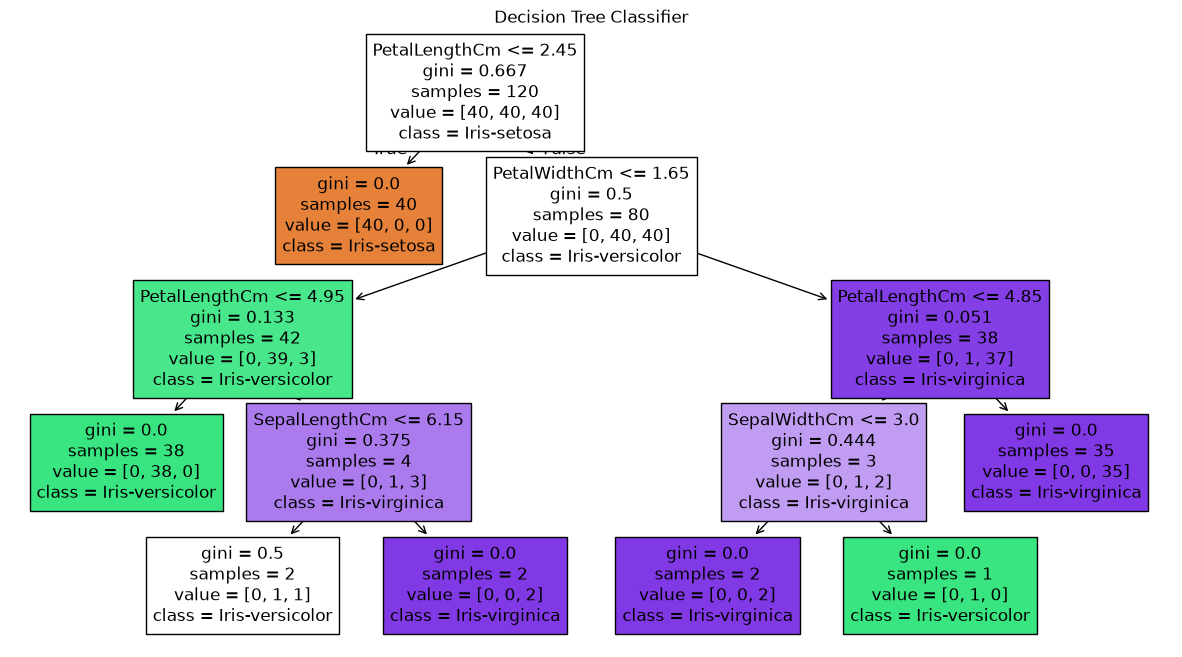

In [22]:
# Visualize Decision Tree
plt.figure(figsize=(15, 8))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True
)

plt.title("Decision Tree Classifier")
plt.show()

# Naïve Bayes Classifier

In [23]:
# Create Gaussian Naïve Bayes Model
nb = GaussianNB()

In [24]:
# Train Naïve Bayes
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[40.,40.,40.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,3.098e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[4.99,3.4 ,1.48,0.25], [5.93,2.75,4.25,1.32], [6.61,2.98,5.58,2.04]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.09,0.16,0.03,0.01], [0.22,0.09,0.19,0.03], [0.46,0.12,0.32,0.07]]"


In [25]:
# Predict Test Data
nb_pred = nb.predict(X_test)

In [26]:
# Calculate Naïve Bayes Metrics
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred, average="weighted")
nb_recall = recall_score(y_test, nb_pred, average="weighted")
nb_f1 = f1_score(y_test, nb_pred, average="weighted")

print("Naïve Bayes")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1-Score :", nb_f1)

Naïve Bayes
Accuracy : 0.9666666666666667
Precision: 0.9696969696969696
Recall   : 0.9666666666666667
F1-Score : 0.9665831244778613


In [27]:
# Naïve Bayes Classification Report
print(
    classification_report(
        y_test,
        nb_pred,
        target_names=label_encoder.classes_
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



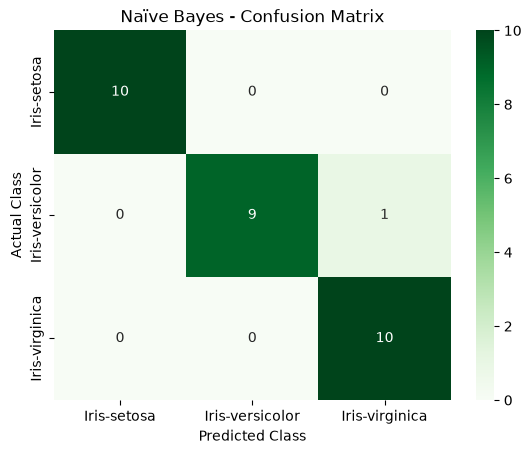

In [28]:
# Naïve Bayes Confusion Matrix
cm_nb = confusion_matrix(y_test, nb_pred)

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Naïve Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

# Comparison of Classifiers

In [29]:
# Create Performance Comparison Table
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Naïve Bayes"],
    "Accuracy": [dt_accuracy, nb_accuracy],
    "Precision": [dt_precision, nb_precision],
    "Recall": [dt_recall, nb_recall],
    "F1-Score": [dt_f1, nb_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.933333,0.933333,0.933333,0.933333
1,Naïve Bayes,0.966667,0.969697,0.966667,0.966583


In [30]:
# Convert Metrics to Percentage
comparison_percentage = comparison.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_percentage[column] = (
        comparison_percentage[column] * 100
    ).round(2)

comparison_percentage

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,93.33,93.33,93.33,93.33
1,Naïve Bayes,96.67,96.97,96.67,96.66


In [31]:
# Identify the Most Suitable Model
best_model = comparison.loc[
    comparison["Accuracy"].idxmax(),
    "Model"
]

print("Most Suitable Model:", best_model)

Most Suitable Model: Naïve Bayes


## Analysis

The Decision Tree and Naïve Bayes classifiers are compared using Accuracy, Precision, Recall, and F1-Score. The confusion matrices show the number of correct and incorrect predictions for each Iris species.

The model with the higher overall evaluation performance is considered more suitable for this dataset.

## Result

Successfully implemented **Decision Tree** and **Naïve Bayes** classifiers using the provided **Kaggle Iris.csv** dataset. Both classifiers were evaluated using standard classification metrics and confusion matrices, and their performance was compared to identify the most suitable model.